<a href="https://colab.research.google.com/github/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution/blob/main/notebooks/05_fusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-signal fusion evaluation

Manuscript sections 3.2 and 3.7, research questions 2 and 3: does combining the three channels beat each channel on its own?

For every test image and every transform (clean, JPEG 90/70/50/30, WebP, downscaling, recompression) the three channels look at the same image:

- **provenance**: AI images are signed `trainedAlgorithmicMedia`, human images `digitalCreation`; re-encoded files lose the manifest, as on most platforms,
- **watermark**: AI images carry the mark at the configured α (4, about 36 dB PSNR), detected with the threshold from notebook 03,
- **CNN**: the trained, temperature-calibrated classifier from notebook 02.

The fusion rule uses a valid credential first, then a detected watermark, then the CNN, and abstains when the CNN is unsure (probability between 0.35 and 0.65).
Each single channel is also scored alone: provenance and watermark abstain when they have nothing to say, the CNN always decides.

Before starting: notebook 01 (data), 02 (trained models) and 03 (watermark threshold) have saved their outputs to Drive.
**Runtime > Change runtime type > T4 GPU** (a CPU runtime works but is much slower). About 20-40 minutes per model.

## 1. Get the code

In [1]:
%cd /content
!rm -rf repo
!git clone https://github.com/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution.git repo
%cd /content/repo
!pip install -q -e ".[train,provenance,dev]"
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (evaluation will be slow)")

/content
Cloning into 'repo'...
remote: Enumerating objects: 451, done.
remote: Counting objects: 100% (215/215), done.
remote: Compressing objects: 100% (162/162), done.
remote: Total 451 (delta 125), reused 73 (delta 44), pack-reused 236 (from 1)
Receiving objects: 100% (451/451), 6.73 MiB | 13.06 MiB/s, done.
Resolving deltas: 100% (225/225), done.
/content/repo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for attribution (pyproject.toml) ... done
GPU: Tesla T4


## 2. Restore the data and link the earlier results from Google Drive

In [2]:
from google.colab import drive
import os
drive.mount("/content/drive")
D = "/content/drive/MyDrive/thesis-data"
ZIP = f"{D}/harmonized.zip"
if not os.path.exists(ZIP):
    raise FileNotFoundError(f"{ZIP} not found: run notebook 01 through step 8 first, it saves the prepared data there")
!unzip -qo $ZIP -d .
for d in ["models", "watermark", "evaluation", "stress_test"]:
    !mkdir -p $D/$d && rm -rf outputs/$d && ln -s $D/$d outputs/$d
ARCHS = ["resnet50", "efficientnet_b0"]
missing = [p for p in ["outputs/watermark/threshold.json"] + [f"outputs/models/{a}/{f}" for a in ARCHS for f in ("best.pt", "calibration.json")]
           if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(f"missing {missing}: run notebook 03 (watermark) and the ResNet-50 / EfficientNet-B0 section of notebook 02 first")
print("models and watermark threshold found")

Mounted at /content/drive
models and watermark threshold found


## 3. Quick check
20 images per class, written to a scratch folder, to make sure everything runs before the full evaluation.

In [3]:
!python scripts/evaluate.py --arch resnet50 --max-images 20 --out /content/smoke

Measuring watermark confidence on 40 validation images (alpha=4.0)
  P(AI | detected) = 0.9970  (TPR 0.9278, FPR 0.0000)
Evaluating 40 images across 9 conditions on cuda; architecture=resnet50; provenance=on; watermark alpha=4.0, threshold=0.03647 (outputs/watermark/threshold.json)
== condition: clean
  provenance_only: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
   watermark_only: coverage=0.500 acc=1.000 f1=1.000 fpr=0.000 ece=0.003
         cnn_only: coverage=1.000 acc=0.850 f1=0.824 fpr=0.000 ece=0.181
     multi_signal: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
== condition: jpeg_q90
  provenance_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
   watermark_only: coverage=0.500 acc=1.000 f1=1.000 fpr=0.000 ece=0.003
         cnn_only: coverage=1.000 acc=0.775 f1=0.743 fpr=0.100 ece=0.153
     multi_signal: coverage=0.925 acc=1.000 f1=1.000 fpr=0.000 ece=0.033
== condition: jpeg_q70
  provenance_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
   watermark_only:

## 4. Full evaluation
First the watermark detector's precision P(AI | detected) is measured on the validation images; fusion uses it as the confidence of a watermark-based decision.
Then every test image is run through every transform. Results go to Google Drive (`thesis-data/evaluation/<model>/`).

In [4]:
!python scripts/evaluate.py --arch resnet50

Measuring watermark confidence on 2980 validation images (alpha=4.0)
  P(AI | detected) = 0.9985  (TPR 0.9284, FPR 0.0013)
Evaluating 2992 images across 9 conditions on cuda; architecture=resnet50; provenance=on; watermark alpha=4.0, threshold=0.03647 (outputs/watermark/threshold.json)
== condition: clean
  provenance_only: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
   watermark_only: coverage=0.499 acc=1.000 f1=1.000 fpr=0.000 ece=0.001
         cnn_only: coverage=1.000 acc=0.830 f1=0.806 fpr=0.048 ece=0.050
     multi_signal: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
== condition: jpeg_q90
  provenance_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
   watermark_only: coverage=0.499 acc=1.000 f1=1.000 fpr=0.000 ece=0.001
         cnn_only: coverage=1.000 acc=0.812 f1=0.786 fpr=0.067 ece=0.064
     multi_signal: coverage=0.965 acc=0.977 f1=0.979 fpr=0.043 ece=0.012
== condition: jpeg_q70
  provenance_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
   watermark_o

In [5]:
!python scripts/evaluate.py --arch efficientnet_b0

Measuring watermark confidence on 2980 validation images (alpha=4.0)
  P(AI | detected) = 0.9985  (TPR 0.9284, FPR 0.0013)
Evaluating 2992 images across 9 conditions on cuda; architecture=efficientnet_b0; provenance=on; watermark alpha=4.0, threshold=0.03647 (outputs/watermark/threshold.json)
== condition: clean
  provenance_only: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
   watermark_only: coverage=0.499 acc=1.000 f1=1.000 fpr=0.000 ece=0.001
         cnn_only: coverage=1.000 acc=0.772 f1=0.725 fpr=0.058 ece=0.108
     multi_signal: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
== condition: jpeg_q90
  provenance_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
   watermark_only: coverage=0.499 acc=1.000 f1=1.000 fpr=0.000 ece=0.001
         cnn_only: coverage=1.000 acc=0.773 f1=0.726 fpr=0.059 ece=0.110
     multi_signal: coverage=0.971 acc=0.979 f1=0.980 fpr=0.041 ece=0.005
== condition: jpeg_q70
  provenance_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
   wate

## 5. Results
**coverage**: share of images the system gave a decision on. **accuracy** and **ECE** are computed on those decided images
(ECE: gap between stated confidence and actual accuracy, lower is better).
**recall** and **FPR** are over all AI / all human images, so an abstention counts as "not flagged"
(FPR = human art wrongly flagged as AI). For fusion, **decided by** shows which channel made the call.

===== resnet50  (watermark P(AI|detected) = 0.9985, measured on validation)
coverage


system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,1.0,0.4987,1.0,1.0000
jpeg_q90,0.0,0.4987,1.0,0.9652
jpeg_q70,0.0,0.4987,1.0,0.9566
jpeg_q50,0.0,0.4987,1.0,0.9385
jpeg_q30,0.0,0.4983,1.0,0.9228
webp_q80,0.0,0.4987,1.0,0.9723
resize_0.5,0.0,0.4987,1.0,0.9833
resize_0.25,0.0,0.1828,1.0,0.9318
recompress_x3,0.0,0.4987,1.0,0.9666


accuracy


system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,1.0,1.0000,0.8302,1.0000
jpeg_q90,NaN,1.0000,0.8125,0.9775
jpeg_q70,NaN,1.0000,0.8035,0.9759
jpeg_q50,NaN,1.0000,0.7911,0.9633
jpeg_q30,NaN,1.0000,0.7637,0.9478
webp_q80,NaN,1.0000,0.7864,0.9859
resize_0.5,NaN,1.0000,0.7303,0.9891
resize_0.25,NaN,0.9707,0.6451,0.7852
recompress_x3,NaN,1.0000,0.8055,0.9820


recall


...

system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,1.0,0.9997,0.8063,1.0000
jpeg_q90,NaN,0.9997,0.7864,0.9787
jpeg_q70,NaN,0.9997,0.7774,0.9774
jpeg_q50,NaN,0.9997,0.7695,0.9666
jpeg_q30,NaN,0.9993,0.7452,0.9540
webp_q80,NaN,0.9997,0.7433,0.9864
resize_0.5,NaN,0.9997,0.6450,0.9894
resize_0.25,NaN,0.5206,0.4690,0.6725
recompress_x3,NaN,0.9997,0.7751,0.9829


ece


system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,0.01,0.0015,0.0505,0.0100
jpeg_q90,NaN,0.0015,0.0639,0.0122
jpeg_q70,NaN,0.0015,0.0618,0.0127
jpeg_q50,NaN,0.0015,0.0676,0.0099
jpeg_q30,NaN,0.0015,0.0877,0.0147
webp_q80,NaN,0.0015,0.0870,0.0155
resize_0.5,NaN,0.0015,0.1479,0.0126
resize_0.25,NaN,0.0278,0.2392,0.1543
recompress_x3,NaN,0.0015,0.0674,0.0152


fusion: share of images decided by each channel


,decided_by_provenance,decided_by_watermark,decided_by_cnn,coverage
condition,,,,
clean,1.0,0.0000,0.0000,1.0000
jpeg_q90,0.0,0.4987,0.4666,0.9652
jpeg_q70,0.0,0.4987,0.4579,0.9566
jpeg_q50,0.0,0.4987,0.4398,0.9385
jpeg_q30,0.0,0.4983,0.4245,0.9228
webp_q80,0.0,0.4987,0.4736,0.9723
resize_0.5,0.0,0.4987,0.4846,0.9833
resize_0.25,0.0,0.1828,0.7490,0.9318
recompress_x3,0.0,0.4987,0.4679,0.9666


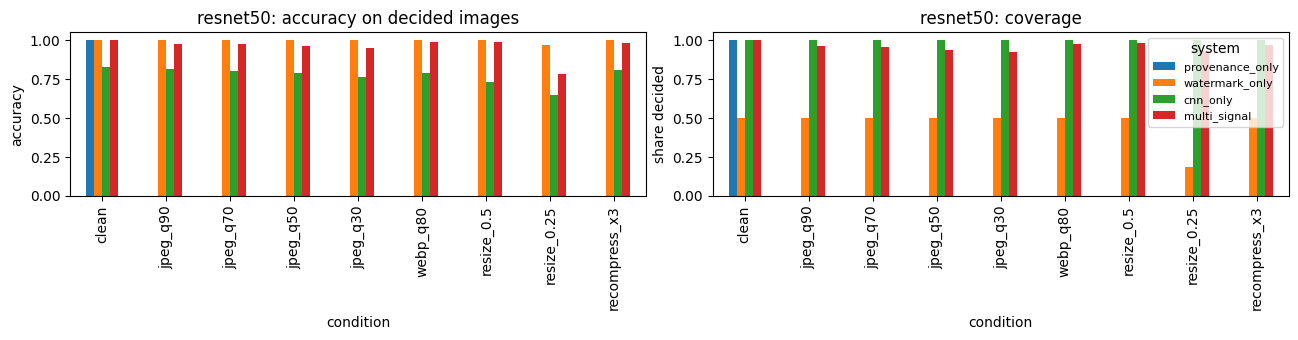

===== efficientnet_b0  (watermark P(AI|detected) = 0.9985, measured on validation)
coverage


system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,1.0,0.4987,1.0,1.0000
jpeg_q90,0.0,0.4987,1.0,0.9706
jpeg_q70,0.0,0.4987,1.0,0.9736
jpeg_q50,0.0,0.4987,1.0,0.9753
jpeg_q30,0.0,0.4983,1.0,0.9766
webp_q80,0.0,0.4987,1.0,0.9756
resize_0.5,0.0,0.4987,1.0,0.9903
resize_0.25,0.0,0.1828,1.0,0.9576
recompress_x3,0.0,0.4987,1.0,0.9766


accuracy


system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,1.0,1.0000,0.7721,1.0000
jpeg_q90,NaN,1.0000,0.7727,0.9787
jpeg_q70,NaN,1.0000,0.7881,0.9852
jpeg_q50,NaN,1.0000,0.7871,0.9863
jpeg_q30,NaN,1.0000,0.7797,0.9843
webp_q80,NaN,1.0000,0.7533,0.9853
resize_0.5,NaN,1.0000,0.6220,0.9943
resize_0.25,NaN,0.9707,0.5809,0.7407
recompress_x3,NaN,1.0000,0.7844,0.9884


recall


...

system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,1.0,0.9997,0.7248,1.0000
jpeg_q90,NaN,0.9997,0.7260,0.9796
jpeg_q70,NaN,0.9997,0.7468,0.9858
jpeg_q50,NaN,0.9997,0.7439,0.9868
jpeg_q30,NaN,0.9993,0.7331,0.9848
webp_q80,NaN,0.9997,0.6897,0.9858
resize_0.5,NaN,0.9997,0.4075,0.9940
resize_0.25,NaN,0.5206,0.2834,0.6053
recompress_x3,NaN,0.9997,0.7394,0.9887


ece


system,provenance_only,watermark_only,cnn_only,multi_signal
condition,,,,
clean,0.01,0.0015,0.1081,0.0100
jpeg_q90,NaN,0.0015,0.1097,0.0050
jpeg_q70,NaN,0.0015,0.0941,0.0089
jpeg_q50,NaN,0.0015,0.1001,0.0112
jpeg_q30,NaN,0.0015,0.1076,0.0112
webp_q80,NaN,0.0015,0.1332,0.0101
resize_0.5,NaN,0.0015,0.2926,0.0072
resize_0.25,NaN,0.0278,0.3506,0.2264
recompress_x3,NaN,0.0015,0.1000,0.0104


fusion: share of images decided by each channel


,decided_by_provenance,decided_by_watermark,decided_by_cnn,coverage
condition,,,,
clean,1.0,0.0000,0.0000,1.0000
jpeg_q90,0.0,0.4987,0.4719,0.9706
jpeg_q70,0.0,0.4987,0.4749,0.9736
jpeg_q50,0.0,0.4987,0.4766,0.9753
jpeg_q30,0.0,0.4983,0.4783,0.9766
webp_q80,0.0,0.4987,0.4769,0.9756
resize_0.5,0.0,0.4987,0.4916,0.9903
resize_0.25,0.0,0.1828,0.7747,0.9576
recompress_x3,0.0,0.4987,0.4779,0.9766


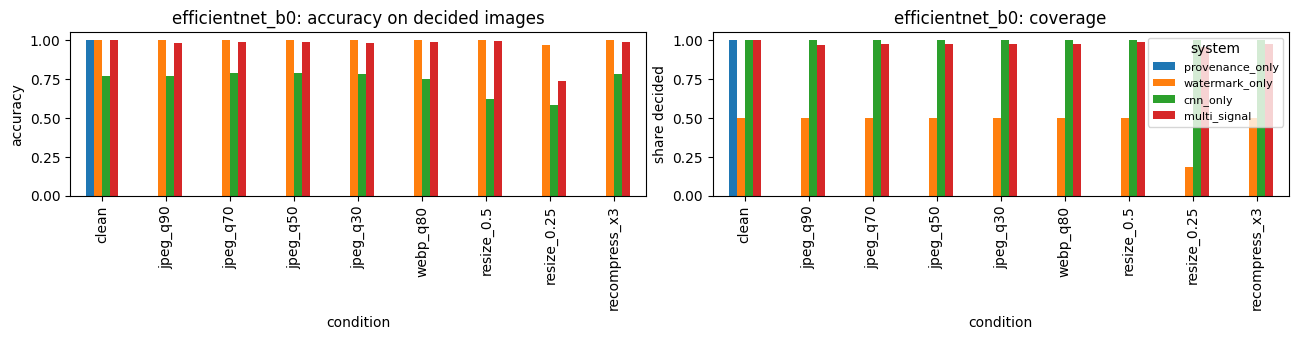

In [6]:
import json, pandas as pd, matplotlib.pyplot as plt
SYSTEMS = ["provenance_only", "watermark_only", "cnn_only", "multi_signal"]
for arch in ARCHS:
    df = pd.read_csv(f"outputs/evaluation/{arch}/summary.csv")
    info = json.load(open(f"outputs/evaluation/{arch}/summary.json"))
    order = df.condition.unique()
    wc = info["watermark_confidence"]
    print(f"===== {arch}  (watermark P(AI|detected) = {wc['confidence']:.4f}, measured on validation)")
    for metric in ["coverage", "accuracy", "recall", "fpr", "f1", "ece"]:
        print(metric)
        display(df.pivot(index="condition", columns="system", values=metric).loc[order, SYSTEMS].round(4))
    print("fusion: share of images decided by each channel")
    display(df[df.system == "multi_signal"].set_index("condition")[["decided_by_provenance", "decided_by_watermark", "decided_by_cnn", "coverage"]].loc[order].round(4))
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
    df.pivot(index="condition", columns="system", values="accuracy").loc[order, SYSTEMS].plot.bar(ax=axes[0], ylim=(0, 1.05), legend=False)
    axes[0].set_title(f"{arch}: accuracy on decided images"); axes[0].set_ylabel("accuracy")
    df.pivot(index="condition", columns="system", values="coverage").loc[order, SYSTEMS].plot.bar(ax=axes[1], ylim=(0, 1.05))
    axes[1].set_title(f"{arch}: coverage"); axes[1].set_ylabel("share decided"); axes[1].legend(title="system", fontsize=8)
    plt.tight_layout(); plt.show()

## 6. Recompute the metrics from the saved per-image results (no GPU needed)
Recall and FPR are now counted over all AI / all human images. Before, FPR was computed only over the images a system decided,
which made the watermark's FPR read 1.0 at `resize_0.25` (it can only ever answer "AI", so it has no true negatives).
This step only rereads `per_image.csv`; it doesn't rerun any model. Then rerun section 5 to see the corrected tables.

In [7]:
for arch in ARCHS:
    !python scripts/evaluate.py --arch $arch --resummarize

Recomputed outputs/evaluation/resnet50/summary.csv and outputs/evaluation/resnet50/summary.json from outputs/evaluation/resnet50/per_image.csv (26928 rows)
Recomputed outputs/evaluation/efficientnet_b0/summary.csv and outputs/evaluation/efficientnet_b0/summary.json from outputs/evaluation/efficientnet_b0/per_image.csv (26928 rows)


## 7. Ablation: no watermark
Does the embedded watermark lower the CNN's accuracy? The CNN-only numbers in section 4 are below the stress test from notebook 02,
and the gap closes as JPEG compression erodes the watermark. This run leaves every image unmarked and switches the watermark channel off
(fusion = provenance → CNN). If the CNN-only results here match notebook 02's stress test, the watermark is what lowered them.
Results go to `thesis-data/evaluation/<model>_no_watermark/`. About as long as section 4.

In [8]:
for arch in ARCHS:
    !python scripts/evaluate.py --arch $arch --no-watermark

Evaluating 2992 images across 9 conditions on cuda; architecture=resnet50; provenance=on; watermark OFF (ablation: AI images unmarked)
== condition: clean
  provenance_only: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
   watermark_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
         cnn_only: coverage=1.000 acc=0.926 f1=0.924 fpr=0.048 ece=0.026
     multi_signal: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
== condition: jpeg_q90
  provenance_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
   watermark_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
         cnn_only: coverage=1.000 acc=0.904 f1=0.901 fpr=0.067 ece=0.017
     multi_signal: coverage=0.906 acc=0.934 f1=0.872 fpr=0.043 ece=0.016
== condition: jpeg_q70
  provenance_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
   watermark_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
         cnn_only: coverage=1.000 acc=0.835 f1=0.819 fpr=0.081 ece=0.035
     multi_signal: coverage=0.867 acc=0.876 f1=0.768 fpr

===== resnet50: CNN-only accuracy


,stress test (nb 02),"fusion run, AI marked","ablation, unmarked",watermark effect
condition,,,,
clean,0.9375,0.8302,0.9265,-0.0963
jpeg_q90,0.9041,0.8125,0.9041,-0.0916
jpeg_q70,0.8346,0.8035,0.8346,-0.0311
jpeg_q50,0.7868,0.7911,0.7868,0.0043
jpeg_q30,0.7500,0.7637,0.7500,0.0137
webp_q80,0.8920,0.7864,0.8920,-0.1056
resize_0.5,0.8820,0.7303,0.8820,-0.1517
resize_0.25,0.7146,0.6451,0.7146,-0.0695
recompress_x3,0.8409,0.8055,0.8409,-0.0354


resnet50: CNN-only recall on AI images (human images are identical in both runs)


,AI marked,unmarked
condition,,
clean,0.7080,0.9009
jpeg_q90,0.6919,0.8754
jpeg_q70,0.6879,0.7502
jpeg_q50,0.6986,0.6899
jpeg_q30,0.6926,0.6651
webp_q80,0.6196,0.8312
resize_0.5,0.4910,0.7950
resize_0.25,0.3141,0.4534
recompress_x3,0.6718,0.7428


resnet50: fusion accuracy and coverage with and without the watermark channel


,fusion with watermark,fusion without watermark,coverage with,coverage without
condition,,,,
clean,1.0000,1.0000,1.0000,1.0000
jpeg_q90,0.9775,0.9344,0.9652,0.9064
jpeg_q70,0.9759,0.8763,0.9566,0.8673
jpeg_q50,0.9633,0.8314,0.9385,0.8386
jpeg_q30,0.9478,0.7951,0.9228,0.8239
webp_q80,0.9859,0.9304,0.9723,0.8927
resize_0.5,0.9891,0.9077,0.9833,0.9054
resize_0.25,0.7852,0.7446,0.9318,0.8820
recompress_x3,0.9820,0.8859,0.9666,0.8727


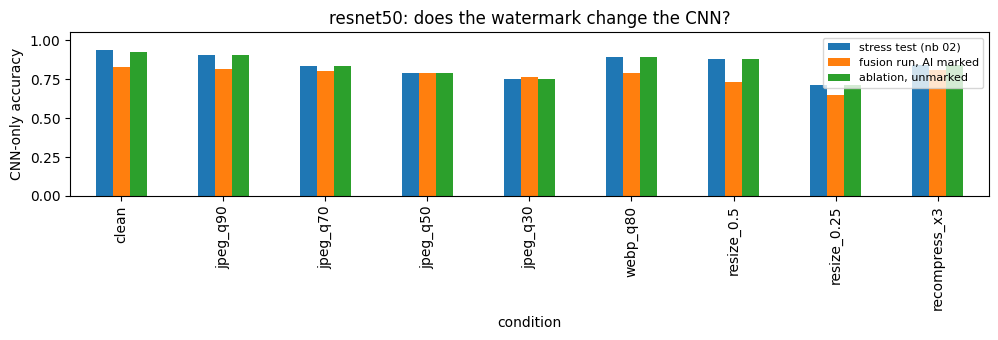

===== efficientnet_b0: CNN-only accuracy


,stress test (nb 02),"fusion run, AI marked","ablation, unmarked",watermark effect
condition,,,,
clean,0.9345,0.7721,0.9348,-0.1628
jpeg_q90,0.9258,0.7727,0.9258,-0.1531
jpeg_q70,0.8737,0.7881,0.8737,-0.0856
jpeg_q50,0.8372,0.7871,0.8372,-0.0501
jpeg_q30,0.8015,0.7797,0.8015,-0.0217
webp_q80,0.9051,0.7533,0.9051,-0.1517
resize_0.5,0.8222,0.6220,0.8222,-0.2002
resize_0.25,0.6277,0.5809,0.6277,-0.0468
recompress_x3,0.8767,0.7844,0.8767,-0.0922


efficientnet_b0: CNN-only recall on AI images (human images are identical in both runs)


,AI marked,unmarked
condition,,
clean,0.6015,0.9277
jpeg_q90,0.6035,0.9102
jpeg_q70,0.6263,0.7977
jpeg_q50,0.6196,0.7200
jpeg_q30,0.6062,0.6497
webp_q80,0.5492,0.8533
resize_0.5,0.2605,0.6618
resize_0.25,0.1661,0.2599
recompress_x3,0.6129,0.7977


efficientnet_b0: fusion accuracy and coverage with and without the watermark channel


,fusion with watermark,fusion without watermark,coverage with,coverage without
condition,,,,
clean,1.0000,1.0000,1.0000,1.0000
jpeg_q90,0.9787,0.9506,0.9706,0.9265
jpeg_q70,0.9852,0.9092,0.9736,0.9054
jpeg_q50,0.9863,0.8797,0.9753,0.8837
jpeg_q30,0.9843,0.8410,0.9766,0.8723
webp_q80,0.9853,0.9380,0.9756,0.9051
resize_0.5,0.9943,0.8587,0.9903,0.8944
resize_0.25,0.7407,0.6449,0.9576,0.9168
recompress_x3,0.9884,0.9113,0.9766,0.9001


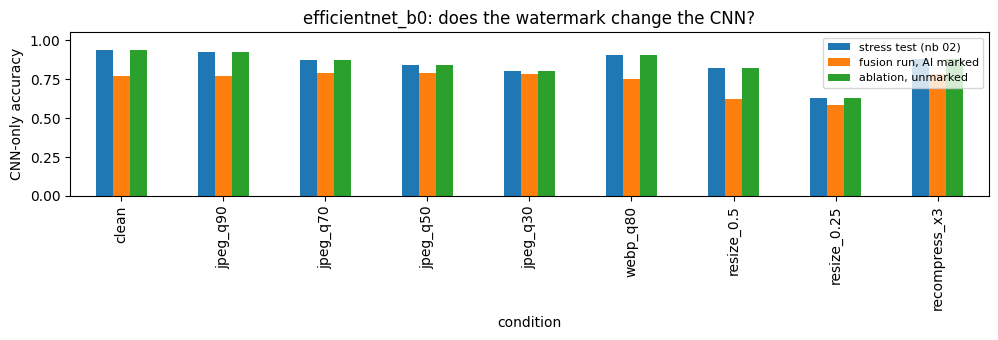

In [9]:
import pandas as pd, matplotlib.pyplot as plt
for arch in ARCHS:
    stress = pd.read_csv(f"outputs/stress_test/{arch}/results.csv").set_index("condition")
    marked = pd.read_csv(f"outputs/evaluation/{arch}/summary.csv")
    plain = pd.read_csv(f"outputs/evaluation/{arch}_no_watermark/summary.csv")
    order = marked.condition.unique()
    cnn = pd.DataFrame({
        "stress test (nb 02)": stress.loc[order, "accuracy"],
        "fusion run, AI marked": marked[marked.system == "cnn_only"].set_index("condition").loc[order, "accuracy"],
        "ablation, unmarked": plain[plain.system == "cnn_only"].set_index("condition").loc[order, "accuracy"],
    })
    cnn["watermark effect"] = cnn["fusion run, AI marked"] - cnn["ablation, unmarked"]
    print(f"===== {arch}: CNN-only accuracy")
    display(cnn.round(4))
    rec = pd.DataFrame({
        "AI marked": marked[marked.system == "cnn_only"].set_index("condition").loc[order, "recall"],
        "unmarked": plain[plain.system == "cnn_only"].set_index("condition").loc[order, "recall"],
    })
    print(f"{arch}: CNN-only recall on AI images (human images are identical in both runs)")
    display(rec.round(4))
    fus = pd.DataFrame({
        "fusion with watermark": marked[marked.system == "multi_signal"].set_index("condition").loc[order, "accuracy"],
        "fusion without watermark": plain[plain.system == "multi_signal"].set_index("condition").loc[order, "accuracy"],
        "coverage with": marked[marked.system == "multi_signal"].set_index("condition").loc[order, "coverage"],
        "coverage without": plain[plain.system == "multi_signal"].set_index("condition").loc[order, "coverage"],
    })
    print(f"{arch}: fusion accuracy and coverage with and without the watermark channel")
    display(fus.round(4))
    ax = cnn.drop(columns="watermark effect").plot.bar(figsize=(10, 3.5), ylim=(0, 1.05))
    ax.set_ylabel("CNN-only accuracy"); ax.set_title(f"{arch}: does the watermark change the CNN?"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()